<a href="https://colab.research.google.com/github/AAMINABIBI/AI-engineering/blob/main/ML/Weekly_Assignment_ML_Linear_Logistic_DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning – Weekly Assignment
**Topics covered (from class notebooks ML 1–4):** Simple & Multiple Linear Regression · Linear Regression on a time-series dataset · Logistic Regression · Decision Tree

**Name:** _______AAMINA BIBI_____________  **Roll No:** ______TRN-2026-001088
______________  **Date:** ________18/11.2026____________

**Total marks: 100**

| Part | Topic | Dataset file | Marks |
|---|---|---|---|
| 1 | Simple & Multiple Linear Regression | `diabetes_progression.csv` | 25 |
| 2 | Linear Regression on date-wise data | `ecommerce_orders_pakistan.csv` | 25 |
| 3 | Logistic Regression | `loan_default.csv` | 30 |
| 4 | Decision Tree Classifier | `phones.csv` | 20 |

**Instructions**
- Put all four CSV files in the same folder as this notebook (in Colab, upload them in the Files panel).
- Write code in the empty cells below each task. Do not delete the task text.
- Where a question asks for an explanation, write it in the markdown cell provided.
- Run **Kernel → Restart & Run All** before submitting to make sure everything works.
- For Part 3, install if needed: `pip install imbalanced-learn`

---
# Part 1: Simple & Multiple Linear Regression (25 marks)
**Dataset:** `diabetes_progression.csv` – 442 patients; target column is `disease_progression`.

**1.1** Import `pandas`, `seaborn`, `matplotlib.pyplot`. Load the CSV and show its first 5 rows. *(2)*

In [82]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('diabetes_progression.csv')
df.head()


,age,sex,bmi,bp,total_cholesterol,ldl,hdl,tch_ratio,log_triglycerides,blood_sugar,disease_progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


**1.2** Draw a scatter plot of `bmi` (x-axis) vs `disease_progression` (y-axis). *(2)*

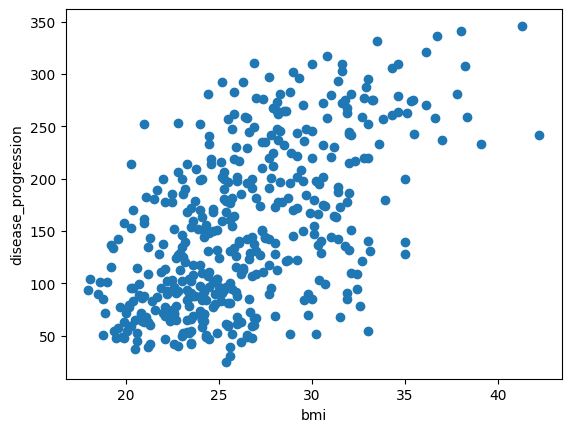

In [83]:
plt.scatter(df['bmi'], df['disease_progression'])
plt.xlabel('bmi')
plt.ylabel('disease_progression')
plt.show()

**1.3** Draw the same scatter plot again with the points coloured by `sex` (use `hue`). *(2)*

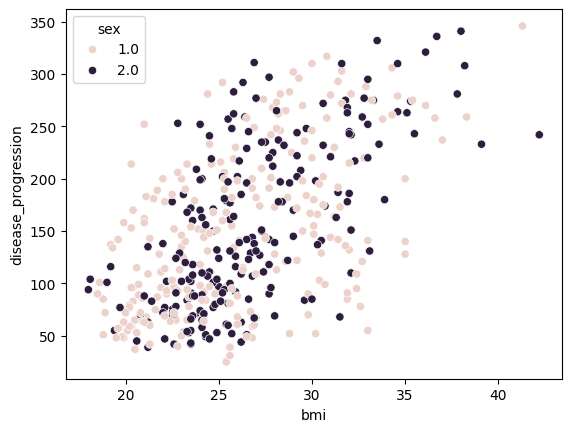

In [84]:
sns.scatterplot(data=df, x='bmi', y='disease_progression', hue='sex')
plt.xlabel('bmi')
plt.ylabel('disease_progression')
plt.show()

**1.4** Make `disease_progression` the dependent variable `y` and `bmi` the independent variable `x`. Split into training and testing sets with 30% in the test set (`train_test_split`). Show the first 5 records of `x_train`, `x_test`, `y_train`, `y_test`. *(4)*

In [85]:
from sklearn.model_selection import train_test_split

x=df[['bmi']]
y=df[['disease_progression']]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)
x_train.head()
x_test.head()
y_train.head()
y_test.head()

,disease_progression
25,202.0
347,88.0
159,195.0
388,110.0
430,183.0


**1.5** Create a `LinearRegression` model and fit it on the training set. Predict on the test set (`y_pred`). *(4)*

In [86]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

**1.6** Compare the first 5 actual values (`y_test`) with the first 5 predicted values (`y_pred`). Then calculate the error using `mean_squared_error`. *(3)*

In [87]:
print(y_test.head())
print(y_pred[0:5])
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test,y_pred)

     disease_progression
25                 202.0
347                 88.0
159                195.0
388                110.0
430                183.0
[[140.86183799]
 [125.09177369]
 [192.11454696]
 [130.01991878]
 [100.45104822]]


4230.878756968202

**1.7** Now apply **Multiple Linear Regression**: keep `y` the same, and use `bmi`, `bp`, `blood_sugar` as the independent variables. Split, fit, predict, and calculate `mean_squared_error`. *(5)*

In [88]:
x=df[['bmi','bp','blood_sugar']]
y=df[['disease_progression']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

mean_squared_error(y_test,y_pred)

3744.3409824513647

**1.8** Compare the two MSE values. Which model performed better and why? *(3)*

**Answer:**

---
# Part 2: Linear Regression on Date-wise Data (25 marks)
**Dataset:** `ecommerce_orders_pakistan.csv` – cumulative orders of an online store by city. `OrdersPlaced` is the dependent variable (like *Confirmed* in the Covid notebook).

**2.1** Load the CSV with the `Date` column parsed as dates (day first). Show `head()` and `tail()`. *(2)*

In [89]:
import pandas as pd
df = pd.read_csv('ecommerce_orders_pakistan.csv', parse_dates=['Date'])
df.head()
df.tail()

,Date,Sno,City,Country,Delivered,Returned,OrdersPlaced
715,30-03-2024,716,Lahore,Pakistan,8271,521,9242
716,30-03-2024,717,Multan,Pakistan,1376,83,1566
717,30-03-2024,718,Peshawar,Pakistan,1722,95,1970
718,30-03-2024,719,Quetta,Pakistan,796,54,915
719,30-03-2024,720,Rawalpindi,Pakistan,2387,145,2812


**2.2** Keep only the columns `Date`, `City`, `Delivered`, `Returned`, `OrdersPlaced` and rename them to `date`, `city`, `delivered`, `returned`, `orders`. *(3)*

In [90]:
df.rename(columns={'Date': 'date', 'City': 'city', 'Delivered': 'delivered', 'Returned': 'returned', 'OrdersPlaced': 'orders'}, inplace=True)
df.head()

,date,Sno,city,Country,delivered,returned,orders
0,01-01-2024,1,Faisalabad,Pakistan,0,0,9
1,01-01-2024,2,Islamabad,Pakistan,0,1,25
2,01-01-2024,3,Karachi,Pakistan,0,2,39
3,01-01-2024,4,Lahore,Pakistan,0,1,26
4,01-01-2024,5,Multan,Pakistan,0,1,10


**2.3** Create a dataframe `today` holding the rows for the last date in the data. Sort it by `orders` (descending) and show the top 5 cities. Draw a bar plot (`sns.barplot`) of these 5 cities. *(4)*

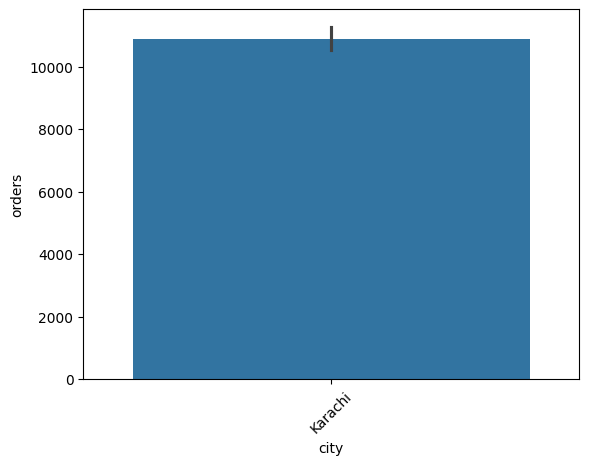

In [91]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# If you want to sort the entire dataframe to find the top cities by orders:
today = df.sort_values(by='orders', ascending=False).head(10)

# Or, if you specifically meant to look at the last row(s) of your dataframe:
# today = df.tail(5)

# Now plot the bar chart safely
sns.barplot(data=today, x='city', y='orders')
plt.xticks(rotation=45)  # Rotates city names if they overlap
plt.show()

**2.4** In the same way, find the top 5 cities by `returned` on that date and draw a bar plot. *(3)*

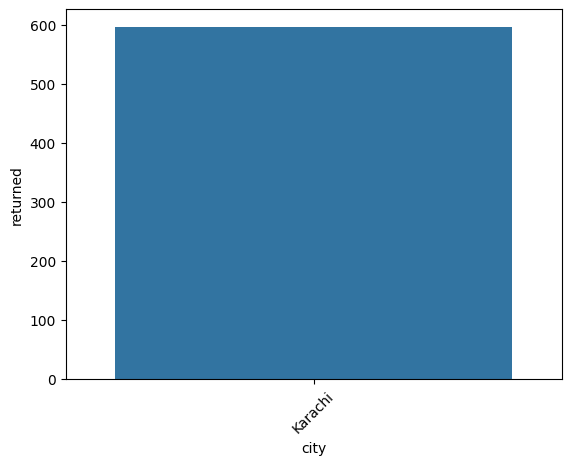

In [92]:
returned=df.sort_values(by='returned', ascending=False).head(5)
sns.barplot(data=returned, x='city', y='returned')
plt.xticks(rotation=45)
plt.show()

[link text](https://)**2.5** Extract the rows of one city of your choice. Draw line plots with `date` on the x-axis for (a) `orders` and (b) `returned`. *(3)*

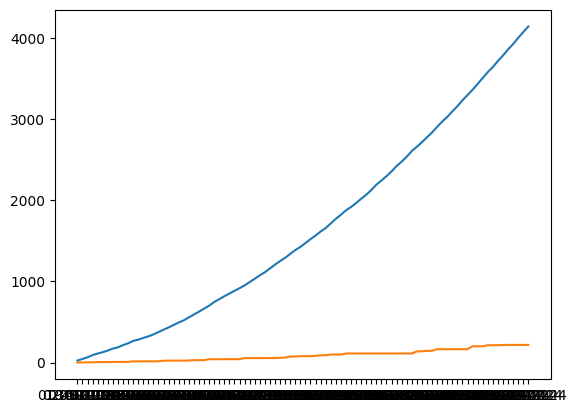

In [93]:

Islamabad=df[df['city']=='Islamabad']
plt.plot(Islamabad['date'],Islamabad['orders'])
plt.plot(Islamabad['date'],Islamabad['returned'])
plt.show()

**2.6** Take `date` as the independent variable and `orders` as the dependent variable. Convert the dates to numeric ordinals so the model can use them, then split into training and testing sets (30% test). *(4)*

In [94]:
df['date_num'] = pd.to_datetime(df['date'], format='%d-%m-%Y').map(pd.Timestamp.toordinal)

x=df[['date_num']]
y=df[['orders']]
from sklearn.model_selection import train_test_split
x_test, x_train, y_test, y_train = train_test_split(x, y, test_size=0.3)
x_train.head()
x_test.head()
y_train.head()
y_test.head()

,orders
149,243
509,1207
483,4865
518,584
680,2127


**2.7** Fit a `LinearRegression` model (reshape the data to 2-D where needed). *(3)*

In [95]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)



```
`# This is formatted as code`
```

**2.8** Convert a date of your choice that is after the last date in the data to an ordinal and predict the number of orders for it. *(3)*

In [96]:
import pandas as pd

# 1. Choose a date after your dataset's date range (make sure it matches your date format)
future_date_str = '15-02-2024'

# 2. Convert that date string into an ordinal number
future_ordinal = pd.Timestamp(future_date_str).toordinal()

# 3. Predict the orders
# (Note: model.predict() expects a 2D array or DataFrame, hence the double brackets [[ ]])
predicted_orders = model.predict([[future_ordinal]])

print(f"Predicted orders for {future_date_str}: {predicted_orders[0][0]:.2f}")

Predicted orders for 15-02-2024: 1927.89


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


---
# Part 3: Logistic Regression (30 marks)
**Dataset:** `loan_default.csv` – columns: `default` (Yes/No), `student` (Yes/No), `balance`, `income`. Target is `default`.

**3.1** Import the required libraries. Load the CSV and show `head()`, `shape` and `describe()`. *(2)*

In [97]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df=pd.read_csv('loan_default.csv')
df.head()
df.shape
df.describe()

,balance,income
count,10000.000000,10000.000000
mean,838.856623,33405.720400
std,480.729920,15390.013481
min,0.000000,800.000000
25%,500.867500,19844.750000
50%,821.890000,33195.500000
75%,1143.497500,44945.500000
max,2698.920000,75000.000000


**3.2** Draw box plots of `balance` and `income` side by side (`plt.subplot`). Which column shows outliers? *(2)*

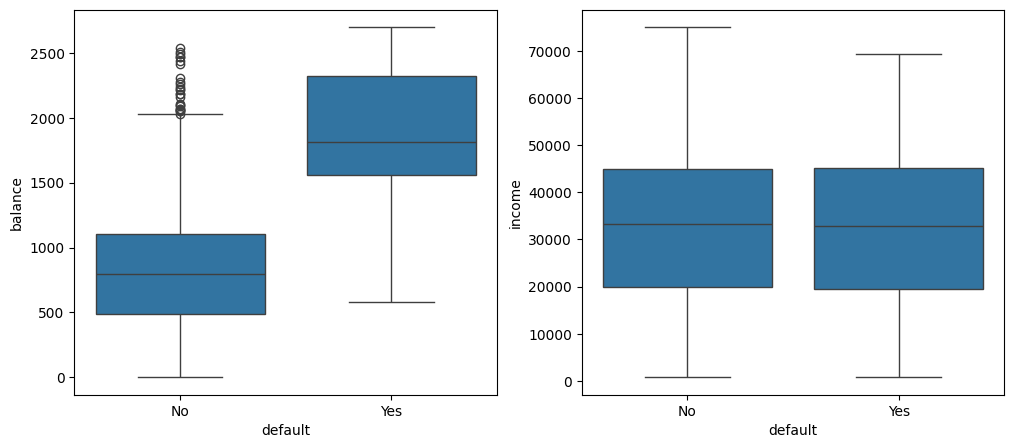

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='default', y='balance', ax=axes[0])
sns.boxplot(data=df, x='default', y='income', ax=axes[1])

plt.show()

**3.3** Univariate analysis of categorical columns: draw count plots for `default` and `student`. Show `value_counts()` and `value_counts(normalize=True)` for both. *(3)*

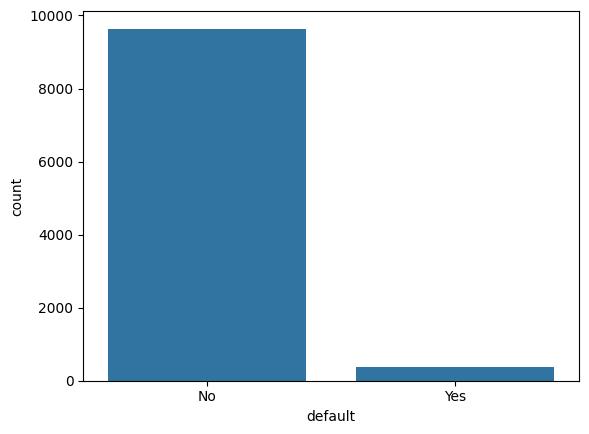

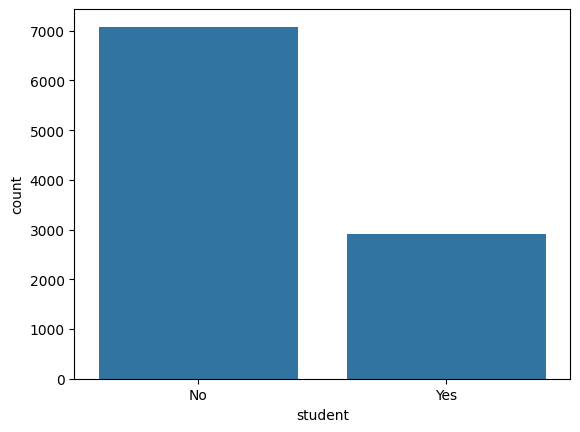

default
No     9637
Yes     363
Name: count, dtype: int64
default
No     0.9637
Yes    0.0363
Name: proportion, dtype: float64
student
No     7081
Yes    2919
Name: count, dtype: int64
student
No     0.7081
Yes    0.2919
Name: proportion, dtype: float64


In [99]:
sns.countplot(data=df, x='default')
plt.show()
sns.countplot(data=df, x='student')
plt.show()
print(df['default'].value_counts())
print(df['default'].value_counts(normalize=True))

print(df['student'].value_counts())
print(df['student'].value_counts(normalize=True))

**3.4** Bivariate analysis: draw box plots of `balance` vs `default` and `income` vs `default`. Create a cross-tabulation of `student` and `default` with `normalize='index'`. *(3)*

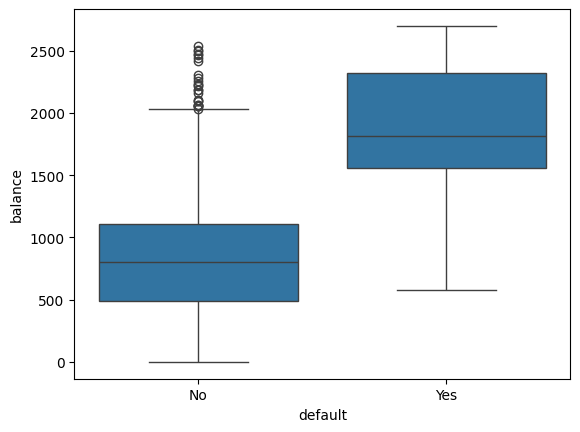

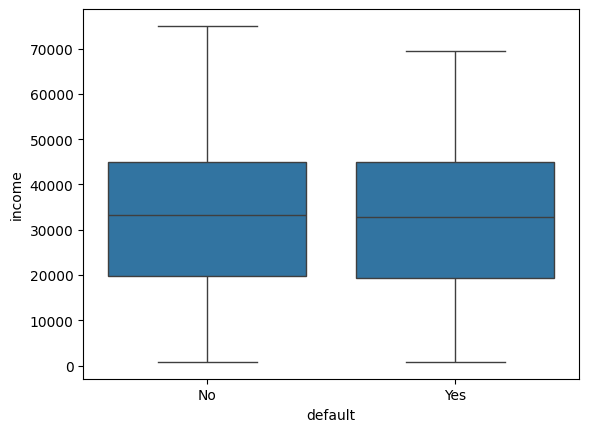

default,No,Yes
student,,
No,0.966671,0.033329
Yes,0.956492,0.043508


In [100]:
sns.boxplot(data=df, x='default', y='balance')
plt.show()
sns.boxplot(data=df, x='default', y='income')
plt.show()
pd.crosstab(df['student'], df['default'], normalize='index')

**3.5** Draw a correlation heatmap for `balance` and `income` (`annot=True`). Check missing values with `isnull().sum()`. *(2)*

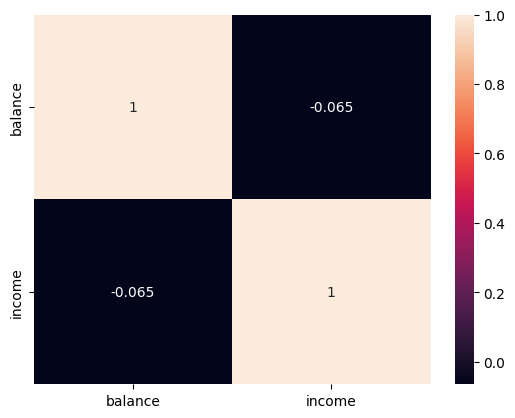

,0
default,0
student,0
balance,0
income,0


In [101]:
sns.heatmap(df[['balance', 'income']].corr(), annot=True)
plt.show()
df.isnull().sum()

**3.6** Find outliers in `balance` using the IQR method: calculate Q1, Q3, IQR, lower limit and upper limit. Count how many records are above the upper limit and what percentage of them are defaulters. *(4)*

In [102]:
Q1 = df['balance'].quantile(0.25)
Q3 = df['balance'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[df['balance'] > upper_limit]
count_outliers = len(outliers)
percentage_outliers = (count_outliers / len(df)) * 100


**3.7** Treat the outliers by setting every value above the upper limit equal to the upper limit (`np.where`). Draw the box plot of `balance` again. *(2)*

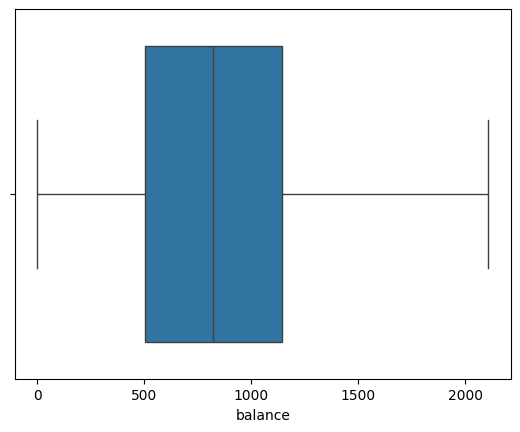

In [103]:
import numpy as np
df['balance'] = np.where(df['balance'] > upper_limit, upper_limit, df['balance'])
sns.boxplot(data=df, x='balance')
plt.show()

**3.8** Convert `default` and `student` from Yes/No to 1/0 using `map`. Make sure `balance` and `income` are numeric. Show `head()`. *(2)*

In [104]:
df["student"]=df['student'].map({'Yes':1,'No':0})
df["default"]=df['default'].map({'Yes':1,'No':0})
df.head()


,default,student,balance,income
0,0,0,1149.21,19050.0
1,0,0,0.00,42748.0
2,0,0,1483.50,64056.0
3,0,1,1240.99,26144.0
4,0,0,1066.94,33524.0


**3.9** Define `x` (all columns except `default`) and `y` (`default`). Split into training and testing sets with `test_size=0.3`, `random_state=21` and `stratify=y`. Print the shapes and the percentage of defaulters in both sets. *(3)*

In [105]:
x=df.drop('default',axis=1)
y=df['default']
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=21, stratify=y)
print(x_train.shape)
print(x_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(7000, 3)
(3000, 3)
default
0    0.963714
1    0.036286
Name: proportion, dtype: float64
default
0    0.963667
1    0.036333
Name: proportion, dtype: float64


**3.10** Apply `SMOTE` on the **training set only** with `sampling_strategy=0.75`. Show the class ratio after resampling. *(2)*

In [106]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy=0.75)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)

print(y_train_resampled.value_counts())



default
0    6746
1    5059
Name: count, dtype: int64


**3.11** Fit a `LogisticRegression` model, predict on the test set, and display the `confusion_matrix`. *(3)*

In [107]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

model=LogisticRegression()
model.fit(x_train_resampled,y_train_resampled)
y_pred=model.predict(x_test)
confusion_matrix(y_test,y_pred)


array([[2608,  283],
       [  16,   93]])

**3.12** Calculate the accuracy from the confusion matrix and also with `accuracy_score`. Show `classification_report`. Briefly comment: is accuracy alone enough here? *(2)*

**Answer:**

In [108]:
acc=(2606+94)/(2606+94+285+15)
print(acc)
accuracy_score(y_test,y_pred)
print(classification_report(y_test,y_pred))

0.9
              precision    recall  f1-score   support

           0       0.99      0.90      0.95      2891
           1       0.25      0.85      0.38       109

    accuracy                           0.90      3000
   macro avg       0.62      0.88      0.66      3000
weighted avg       0.97      0.90      0.93      3000



**3. Is accuracy alone enough here?**


No, accuracy alone is not enough.

Because this is an imbalanced dataset (notice the large difference between the negative class samples and positive class samples), accuracy can be extremely misleading. A model that blindly predicts the majority class every single time could easily achieve a high overall accuracy while completely failing to catch any of the actual positive/rare cases.

That is why you must check the Classification Report, which provides Precision, Recall, and F1-score to see how well the model performs on each individual class.

---
# Part 4: Decision Tree Classifier (20 marks)
**Dataset:** `phones.csv` – columns: `Model_ID`, `Brand`, `Segment`, `Speed_GHz`, `RAM_GB`, `Camera_MP`, `Battery_mAh`, `Price_PKR`, `Flagship` (Yes/No).

**4.1** Load the CSV and show `head()`. Rename the column `Brand` to `primary_brand` and `Segment` to `secondary_segment` (`rename` with `inplace=True`). *(2)*

In [109]:
import pandas as pd
df=pd.read_csv('phones.csv')
df.head()
df.rename(columns={'Brand': 'primary_brand', 'Segment': 'secondary_segment'}, inplace=True)
df.head()

,Model_ID,primary_brand,secondary_segment,Speed_GHz,RAM_GB,Camera_MP,Battery_mAh,Price_PKR,Flagship
0,1,Samsung,Battery,2.41,6,32.0,4857.0,105800.0,No
1,2,Oppo,NaN,3.18,16,97.0,5136.0,217700.0,Yes
2,3,Oppo,NaN,2.23,3,48.0,5075.0,67600.0,No
3,4,Infinix,Battery,1.54,8,47.0,4043.0,115900.0,No
4,5,Infinix,NaN,2.49,6,24.0,5463.0,95900.0,No


**4.2** Extract all rows where `primary_brand` is `Samsung` into `samsung_phones`, and all rows where it is `Xiaomi` into `xiaomi_phones`. Show `shape` and `head()` of each. *(3)*

In [110]:
df['Samsung']=df['primary_brand']=='Samsung'
df['Xiaomi']=df['primary_brand']=='Xiaomi'
samsung_phones=df[df['Samsung']==True]
xiaomi_phones=df[df['Xiaomi']==True]
print(samsung_phones.shape)
samsung_phones.head()
print(xiaomi_phones.shape)
xiaomi_phones.head()

(195, 11)
(178, 11)


,Model_ID,primary_brand,secondary_segment,Speed_GHz,RAM_GB,Camera_MP,Battery_mAh,Price_PKR,Flagship,Samsung,Xiaomi
7,8,Xiaomi,Gaming,2.79,4,8.0,4031.0,49100.0,No,False,True
15,16,Xiaomi,Gaming,1.93,6,79.0,4531.0,115200.0,No,False,True
17,18,Xiaomi,NaN,3.05,6,58.0,4255.0,157700.0,No,False,True
22,23,Xiaomi,Gaming,2.41,4,12.0,5714.0,65400.0,No,False,True
24,25,Xiaomi,Camera,1.85,6,63.0,4037.0,94400.0,No,False,True


**4.3** For `samsung_phones`, draw histograms (`sns.histplot`) of `Speed_GHz` and `Camera_MP`, and show `describe()`. Describe in one or two lines what you see. *(3)*

**Answer:**

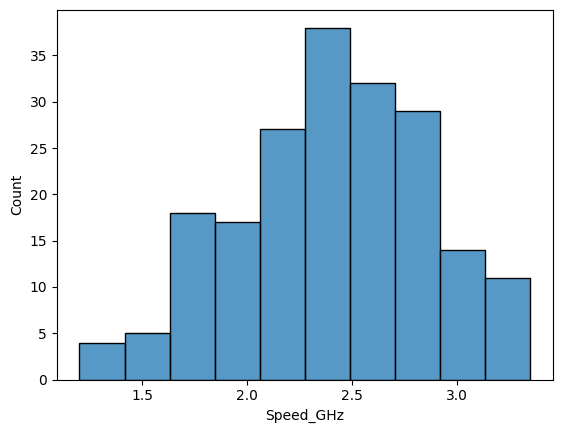

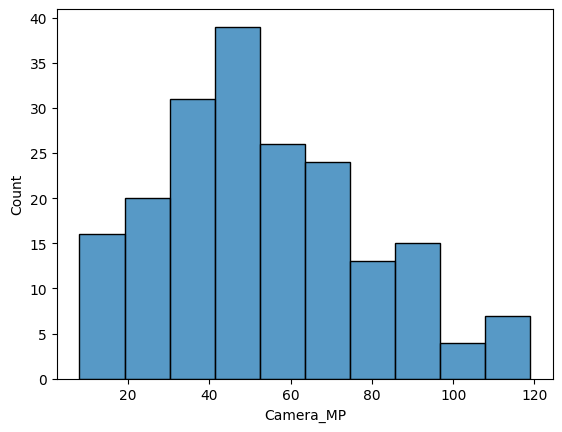

,Model_ID,Speed_GHz,RAM_GB,Camera_MP,Battery_mAh,Price_PKR
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,417.123077,2.407179,5.717949,53.410256,4773.128205,96898.461538
std,230.233398,0.459541,3.018403,25.316876,568.357580,35017.098146
min,1.000000,1.200000,3.000000,8.000000,3277.000000,25900.000000
25%,216.000000,2.130000,4.000000,35.500000,4426.000000,74700.000000
50%,455.000000,2.420000,4.000000,50.000000,4748.000000,90400.000000
75%,619.000000,2.755000,6.000000,70.000000,5118.500000,109000.000000
max,799.000000,3.350000,16.000000,119.000000,6399.000000,221400.000000


In [111]:
sns.histplot(data=samsung_phones, x='Speed_GHz')
plt.show()
sns.histplot(data=samsung_phones, x='Camera_MP')
plt.show()
samsung_phones.describe()

**4.4** Repeat the histograms and `describe()` for `xiaomi_phones`. *(2)*

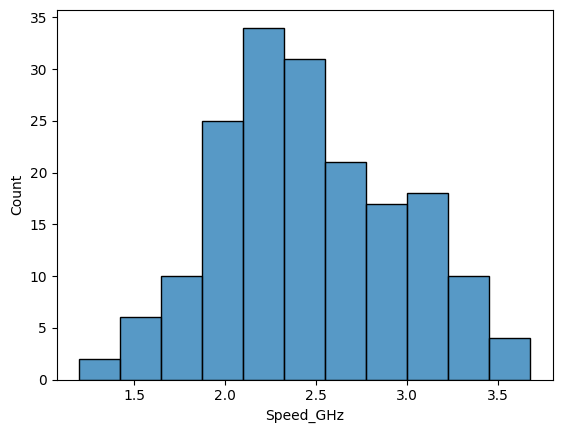

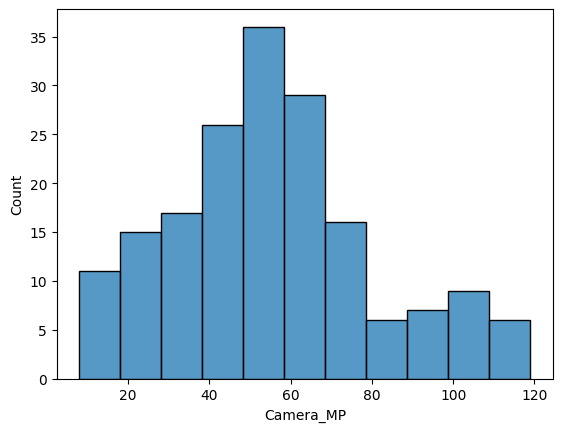

,Model_ID,Speed_GHz,RAM_GB,Camera_MP,Battery_mAh,Price_PKR
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,433.207865,2.456348,6.325843,55.460674,4719.915730,104012.359551
std,232.312415,0.504678,3.586778,25.314767,565.543855,41539.396099
min,8.000000,1.200000,3.000000,8.000000,3149.000000,27600.000000
25%,227.750000,2.120000,4.000000,39.000000,4389.250000,76050.000000
50%,439.000000,2.410000,6.000000,52.000000,4715.000000,94000.000000
75%,663.250000,2.790000,8.000000,68.000000,5109.000000,117775.000000
max,800.000000,3.680000,16.000000,119.000000,6035.000000,224000.000000


In [112]:
sns.histplot(data=xiaomi_phones, x='Speed_GHz')
plt.show()
sns.histplot(data=xiaomi_phones, x='Camera_MP')
plt.show()
xiaomi_phones.describe()

**4.5** Check `value_counts()` of `Flagship`. Is the dataset balanced or imbalanced? Explain. *(2)*

**Answer:**

In [113]:
val=df['Flagship'].value_counts()
print(val)

Flagship
No     696
Yes    104
Name: count, dtype: int64


The dataset is imbalanced.

**4.6** Classify whether a phone is a flagship using `Speed_GHz` only: define `x` and `y`, then split into training and testing sets (30% test). *(2)*

In [114]:
from sklearn.model_selection import train_test_split
x=df[['Speed_GHz']]
y=df['Flagship']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3)

**4.7** Create a `DecisionTreeClassifier`, fit it on the training set and predict on the test set. *(3)*

In [115]:
from sklearn.tree import DecisionTreeClassifier


model=DecisionTreeClassifier()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)

**4.8** Display the `confusion_matrix` and calculate the accuracy (using `accuracy_score`). *(3)*

In [116]:
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score
confusion_matrix(y_test,y_pred)
accuracy_score(y_test,y_pred)


0.8875

---
### Submission checklist
- [✔️ ] All cells run without errors (Restart & Run All)
- [ ✔️] Every written answer is filled in
- [✔️ ] Notebook saved with your name and roll number at the top